# Planejamento de Capacidade de Servidores — Métodos Numéricos (2ª GQ)

**Problema 3 | Ciência da Computação | UNICAP | 2026.2**  

**Objetivo:** construir e justificar um modelo de demanda de armazenamento, estimar o mês 13 e determinar os primeiros meses em que a capacidade atual e os planos de expansão serão ultrapassados.  
**Fontes dos dados:** `data/armazenamento.csv` e `data/expansoes.csv` (materiais fornecidos com o enunciado).

**Nota:** os métodos numéricos estão implementados exclusivamente no pacote `src/metodos_capacidade/`; este notebook apenas os importa, aplica e interpreta.

## Resumo executivo

O estudo ajusta funções polinomiais aos 12 registros mensais de armazenamento por **mínimos quadrados**. Os coeficientes são calculados por **eliminação de Gauss com pivotamento parcial**, aplicada às equações normais. Para identificar os instantes em que a demanda atinge limites de capacidade, emprega-se **bisseção** em uma equação contínua com mudança de sinal. Por fim, verifica-se a condição estrita de ultrapassagem nos meses inteiros.

A escolha de métodos decorre das perguntas do **Problema 3**, e não da obrigação de utilizar todos os conteúdos da disciplina. A análise distingue qualidade do ajuste, validação temporal, precisão da solução numérica e incerteza da previsão.

## 1. Contextualização e fundamentação teórica

O problema de **planejamento de capacidade** parte de 12 observações mensais de armazenamento (em TB), de uma capacidade atual de **600 TB** e de três alternativas de expansão. A decisão prática é antecipar a demanda antes que ela supere a infraestrutura disponível. O enunciado solicita: **(a)** uma função de crescimento justificada; **(b)** uma previsão para o mês seguinte; **(c)** o primeiro mês que excede 600 TB; e **(d)** os primeiros meses que excedem as capacidades dos planos.

### 1.1. Aproximação polinomial e Mínimos Quadrados

As observações não definem, por si sós, uma lei exata de crescimento. Um polinômio interpolador de grau até 11 poderia passar por todos os 12 pontos distintos, mas **erro zero nos dados observados não é sinônimo de boa previsão**: o polinômio pode reproduzir flutuações locais e apresentar comportamento inadequado fora do intervalo. Para estudar uma **tendência**, optamos por ajustar modelos de baixa complexidade usando **Mínimos Quadrados**, conteúdo de aproximação de funções tratado por Ruggiero e Lopes (cap. 6) e no material da disciplina sobre ajuste polinomial.

Para o grau $d$, definimos $P_d(m)=a_0+a_1m+\cdots+a_dm^d$ e escolhemos os coeficientes que minimizam

$$S(a_0,\ldots,a_d)=\sum_{i=1}^{12}\big[y_i-P_d(m_i)\big]^2.$$

O resíduo $r_i=y_i-P_d(m_i)$ mede, em TB, a diferença entre o observado e o ajustado. Elevar os resíduos ao quadrado impede que sinais positivos e negativos se cancelem e penaliza desvios maiores. **Aproximação polinomial** designa o tipo de modelo; **Mínimos Quadrados** designa o critério utilizado para estimar seus coeficientes.

### 1.2. Por que surge um sistema linear?

Ao derivar $S$ em relação a cada coeficiente e igualar as derivadas a zero, obtemos as **equações normais**, um sistema linear para os coeficientes. Para o modelo quadrático, com $P_2(m)=a_0+a_1m+a_2m^2$:

$$\begin{bmatrix}n&\sum m_i&\sum m_i^2\\\sum m_i&\sum m_i^2&\sum m_i^3\\\sum m_i^2&\sum m_i^3&\sum m_i^4\end{bmatrix}\begin{bmatrix}a_0\\a_1\\a_2\end{bmatrix}=\begin{bmatrix}\sum y_i\\\sum m_iy_i\\\sum m_i^2y_i\end{bmatrix}.$$

A **Eliminação de Gauss com pivotamento parcial** foi implementada para resolver esse sistema: a triangularização elimina incógnitas sucessivamente, e a substituição retroativa determina os coeficientes. O pivotamento troca linhas para evitar pivôs nulos ou excessivamente pequenos, reduzindo riscos numéricos. Como as equações normais podem ser mal condicionadas, o pacote também **centraliza e escala os meses antes do ajuste**; isso melhora a escala das potências, embora não elimine toda limitação de estabilidade. Não utilizamos solucionadores prontos para executar essa etapa (Ruggiero e Lopes, cap. 3; material de Eliminação de Gauss da disciplina).

### 1.3. Por que resolver uma equação de raiz?

Uma vez conhecida $P(m)$, a igualdade entre demanda e capacidade $C$ ocorre quando $F_C(m)=P(m)-C=0$. A **Bisseção** localiza esse cruzamento em um intervalo $[a,b]$ com $F_C(a)F_C(b)<0$, desde que $F_C$ seja contínua. A cada iteração, conserva-se a metade que contém a mudança de sinal; portanto, a raiz permanece confinada. Preferimos essa propriedade verificável à maior velocidade potencial de outros métodos, como Newton, que exigiria uma estimativa inicial e cuidados adicionais de convergência (Ruggiero e Lopes, cap. 2).

**Atenção:** encontrar $P(m)=C$ não responde sozinho à pergunta «em qual mês a capacidade será *ultrapassada*?». Depois da raiz contínua, é preciso encontrar o **primeiro mês inteiro** com $P(m)>C$.

## 2. Justificativa dos métodos e decisões de modelagem

| Pergunta ou etapa | Decisão adotada | Justificativa vinculada ao problema | Cuidados e alternativas |
|---|---|---|---|
| **(a)** Encontrar uma função de crescimento | Comparar aproximações polinomiais de graus **1, 2 e 3** por Mínimos Quadrados | Os dados são observações mensais e queremos uma tendência que possa ser avaliada no mês 13; não é necessário passar exatamente por cada ponto | Interpolação exata pode ajustar flutuações; um grau maior pode melhorar o ajuste histórico e piorar a extrapolação |
| Calcular coeficientes | Resolver as equações normais por **Eliminação de Gauss com pivotamento parcial** | O critério de Mínimos Quadrados produz um sistema linear; o método foi estudado na disciplina e implementado pelo grupo | Equações normais amplificam problemas de condicionamento; centralização e escala ajudam, mas não substituem análise de estabilidade |
| **(b)** Prever o próximo mês | Calcular **$P(13)$** | A função já está determinada: é uma avaliação direta, não um novo problema de raiz ou integração | É **extrapolação**, porque só observamos até o mês 12 |
| **(c)–(d)** Encontrar igualdade com cada capacidade | Resolver **$P(m)-C=0$** por Bisseção | O modelo é contínuo; com intervalo que apresenta mudança de sinal, o método mantém a raiz confinada | A tolerância controla o cálculo da raiz, **não** a incerteza do crescimento futuro |
| **(c)–(d)** Informar o primeiro mês de ultrapassagem | Conferir **$P(m-1)\le C<P(m)$** para meses inteiros | O enunciado usa «ultrapassar», isto é, desigualdade **estrita** | Arredondar a raiz sem verificar a desigualdade pode produzir resposta errada |

**Por que não aplicar todos os conteúdos da disciplina?** O objetivo geral reúne diferentes métodos numéricos, mas este problema requer especificamente ajuste de tendência, resolução do sistema associado e busca de cruzamentos. **Integração numérica** calcularia uma área ou acumulação que não foi solicitada; aplicá-la sem uma grandeza a integrar não contribuiria para os quatro itens.

**Critério de decisão:** primeiro verificamos se os modelos representam os dados; depois avaliamos sua capacidade de prever meses posteriores; por fim, preferimos o menor grau que oferece desempenho satisfatório. Não escolhemos um polinômio apenas porque ele produz o menor erro dentro da amostra.

## 3. Dados fornecidos e formulação do problema

Os arquivos `armazenamento.csv` e `expansoes.csv` são a base empírica da análise. Cada par $(m_i,y_i)$ corresponde a um mês e ao armazenamento observado em TB. Os meses 1 a 12 compõem o histórico disponível; não presumimos que sejam uma amostra suficiente para descrever o comportamento de longo prazo.

A capacidade atual é **600 TB**. As expansões acrescentam **100, 200 e 300 TB**, totalizando **700, 800 e 900 TB**. Para cada limite $C$, a pergunta é identificar o menor **mês inteiro futuro** para o qual $P(m)>C$.

A inspeção gráfica inicial permite observar tendência, curvatura e possíveis oscilações antes da escolha de um modelo.

In [ ]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt
from metodos_capacidade.dados import ler_armazenamento, ler_expansoes
from metodos_capacidade.modelos import (ajustar_polinomio, avaliar_polinomio,
    metricas_ajuste, validacao_deixando_um_fora, coeficientes_em_x)
from metodos_capacidade.raizes import bissecao, primeiro_mes_ultrapassagem

PASTA_ATUAL = Path.cwd().resolve()
if (PASTA_ATUAL / 'data' / 'armazenamento.csv').is_file():
    RAIZ = PASTA_ATUAL
elif (PASTA_ATUAL.parent / 'data' / 'armazenamento.csv').is_file():
    RAIZ = PASTA_ATUAL.parent
else:
    raise FileNotFoundError('Execute o notebook na raiz do projeto ou na pasta notebooks/.')
DADOS = RAIZ / 'data'
RESULTADOS = RAIZ / 'resultados'
RESULTADOS.mkdir(parents=True, exist_ok=True)
meses, volumes = ler_armazenamento(DADOS / 'armazenamento.csv')
planos = ler_expansoes(DADOS / 'expansoes.csv')
print('Meses observados:', len(meses), '| intervalo:', int(meses[0]), 'a', int(meses[-1]))
print('Volume inicial e final:', volumes[0], 'TB e', volumes[-1], 'TB')
print('Expansoes:', planos)

Meses observados: 12 | intervalo: 1 a 12
Volume inicial e final: 137.99 TB e 519.14 TB
Expansoes: {'A': 100.0, 'B': 200.0, 'C': 300.0}


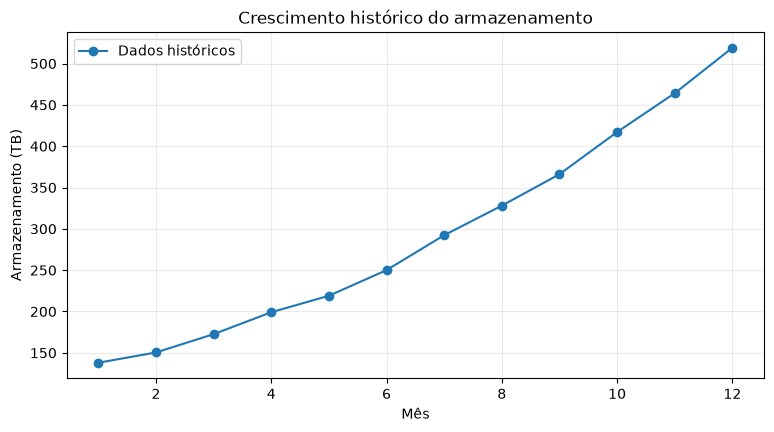

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(meses, volumes, 'o-', label='Dados históricos')
ax.set(xlabel='Mês', ylabel='Armazenamento (TB)', title='Crescimento histórico do armazenamento')
ax.grid(alpha=.25); ax.legend(); plt.show()

## 4. Item (a) — Construção e comparação dos modelos

### 4.1. Procedimento matemático

Ajustamos polinômios de graus **1 (reta), 2 (parábola) e 3 (cúbico)**. A comparação entre graus é importante: uma reta é simples, mas pode não captar aceleração do crescimento; um cúbico é mais flexível, mas também pode reproduzir variações específicas dos 12 registros. O grau 2 é uma hipótese intermediária, **não uma conclusão antecipada**.

Para cada grau, minimizamos $S=\sum_i[y_i-P_d(m_i)]^2$. As condições $\partial S/\partial a_k=0$ resultam em

$$\sum_{j=0}^{d}a_j\left(\sum_{i=1}^{n}m_i^{j+k}\right)=\sum_{i=1}^{n}y_im_i^k,\qquad k=0,\ldots,d.$$

No código, os meses são centralizados e escalados antes da montagem das equações normais; a Eliminação de Gauss com pivotamento parcial calcula os coeficientes nessa escala. Depois, a função `coeficientes_em_x` apresenta o polinômio na variável original $m$.

### 4.2. Como interpretar as métricas?

- **RMSE do ajuste** (*Root Mean Squared Error*): $\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i(y_i-\widehat y_i)^2}$. Mede o tamanho típico dos desvios quadráticos na **mesma unidade dos dados (TB)**. Menor RMSE significa maior proximidade aos pontos avaliados, mas não necessariamente melhor previsão futura.
- **$R^2$ (coeficiente de determinação):** mede a redução proporcional da soma dos quadrados dos resíduos em relação à referência que usa a média observada. Valores próximos de 1 indicam bom ajuste **na amostra**, não validade física do modelo.
- **Validação Leave-One-Out (LOOCV):** em cada uma das 12 repetições, retiramos um mês, ajustamos com os **outros 11** e estimamos o mês omitido. O RMSE dessas 12 estimativas resume o erro de validação interna. Ele ajuda a avaliar a dependência do ajuste em relação aos pontos individuais, **mas usa meses posteriores para prever meses anteriores**; portanto, não reproduz uma previsão cronológica real.

**Decisão metodológica:** combinaremos essas métricas com uma validação temporal separada. Nenhuma delas, isoladamente, demonstra que um polinômio continuará descrevendo a demanda por muitos meses.

In [3]:
modelos = {grau: ajustar_polinomio(meses, volumes, grau) for grau in (1, 2, 3)}
comparacao = {}
for grau, mod in modelos.items():
    met = metricas_ajuste(mod, meses, volumes)
    met['rmse_loo'] = validacao_deixando_um_fora(meses, volumes, grau)
    comparacao[grau] = met
    print(f"Grau {grau}: RMSE={met['rmse']:.4f} TB | R²={met['r2']:.6f} | RMSE LOOCV={met['rmse_loo']:.4f} TB")

modelo = modelos[2]
c0, c1, c2 = coeficientes_em_x(modelo)
print(f'Função selecionada: P(m) = {c2:.8f}m² + {c1:.8f}m + {c0:.8f} (TB)')

Grau 1: RMSE=20.2745 TB | R²=0.972195 | RMSE LOOCV=26.1529 TB
Grau 2: RMSE=2.5099 TB | R²=0.999574 | RMSE LOOCV=3.1127 TB
Grau 3: RMSE=2.5042 TB | R²=0.999576 | RMSE LOOCV=3.4330 TB
Função selecionada: P(m) = 1.90765984m² + 9.92926823m + 125.14568182 (TB)


### 4.3. Decisão inicial sobre o grau

Os resultados da tabela acima permitem comparar três aspectos: **erro histórico**, **erro ao omitir observações** e **complexidade do modelo**. O modelo linear é uma referência simples, mas seu erro maior sugere que uma reta não captura toda a curvatura dos 12 meses. O quadrático introduz um termo $m^2$, permitindo representar uma taxa de crescimento que varia ao longo do tempo. O cúbico adiciona outro parâmetro e pode reduzir o erro de treinamento, mas essa flexibilidade extra precisa ser justificada por melhoria também na validação.

Neste conjunto de dados, o **grau 2 reduz substancialmente o RMSE e o RMSE Leave-One-Out em relação ao grau 1**. O grau 3 apresenta ganho histórico pequeno e pior resultado Leave-One-Out do que o grau 2. Assim, **o grau 2 é o candidato preferido**, sujeito à confirmação por uma avaliação que respeite a ordem dos meses.

Chamamos essa escolha de **parcimônia**: quando aumentar a complexidade não traz ganho convincente fora dos dados usados no ajuste, preferimos a alternativa mais simples. Isso **não** prova que a demanda real obedeça a uma lei quadrática.

### 4.4. Validação temporal: simular uma previsão futura

Como o item (b) exige prever o **mês 13**, a avaliação mais pertinente deve respeitar a ordem cronológica. Reservamos os **meses 10, 11 e 12** para validação e ajustamos, separadamente, os modelos de graus 1, 2 e 3 usando **somente os meses 1 a 9**. Cada modelo então estima os três meses seguintes **sem ter visto seus valores**.

O RMSE temporal é calculado com essas três diferenças entre previsto e observado. Esse teste é mais próximo da situação real do problema do que o Leave-One-Out, porque não utiliza dados futuros para construir a previsão de um mês anterior.

**Limitação do experimento:** há apenas três observações de validação e uma única divisão temporal. O resultado pode mudar se a janela de treinamento mudar; não é um intervalo de confiança nem uma garantia de acerto para os meses 13 em diante. Depois de selecionar o grau, **reajustamos o modelo final com os 12 meses** para aproveitar todo o histórico disponível.

In [4]:
from math import sqrt

meses_treino, volumes_treino = meses[:9], volumes[:9]
meses_teste, volumes_teste = meses[9:], volumes[9:]
validacao_temporal = {}
for grau in (1, 2, 3):
    modelo_treino = ajustar_polinomio(meses_treino, volumes_treino, grau)
    previstos = [avaliar_polinomio(modelo_treino, m) for m in meses_teste]
    rmse_teste = sqrt(sum((p-y)**2 for p,y in zip(previstos, volumes_teste))/len(volumes_teste))
    validacao_temporal[grau] = rmse_teste
    print(f'Grau {grau}: RMSE temporal (meses 10–12) = {rmse_teste:.4f} TB; previsões = {[round(v,2) for v in previstos]}')
assert validacao_temporal[2] < validacao_temporal[1]
assert validacao_temporal[2] < validacao_temporal[3]

Grau 1: RMSE temporal (meses 10–12) = 60.9091 TB; previsões = [379.73, 408.66, 437.59]
Grau 2: RMSE temporal (meses 10–12) = 2.2880 TB; previsões = [414.03, 463.54, 516.79]
Grau 3: RMSE temporal (meses 10–12) = 11.4213 TB; previsões = [410.44, 455.63, 502.6]


**Interpretação da validação temporal.** Na divisão utilizada (treinamento nos meses 1–9 e validação nos meses 10–12), o grau 2 apresenta o menor RMSE de previsão. Isso **reforça**, mas não demonstra definitivamente, sua escolha: o teste contém apenas três meses e não cobre mudanças de regime, sazonalidade ou eventos inesperados. O grau 3, apesar da flexibilidade, não apresenta vantagem preditiva nessa avaliação. Portanto, adotamos **o polinômio quadrático** como modelo de trabalho e registramos explicitamente a incerteza associada à extrapolação.

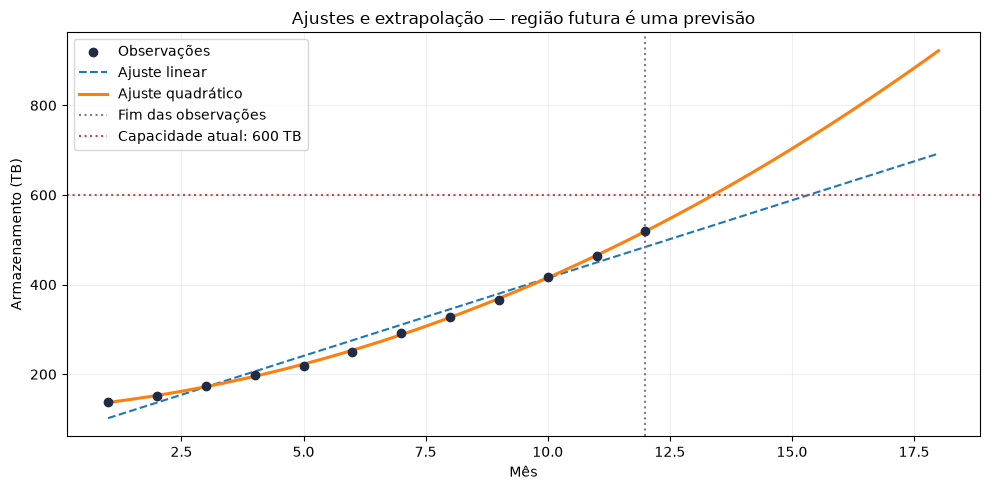

In [5]:
xs = [1 + k * 0.1 for k in range(171)] 
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(meses, volumes, color='#202b44', label='Observações', zorder=4)
ax.plot(xs, [avaliar_polinomio(modelos[1], t) for t in xs], '--', label='Ajuste linear')
ax.plot(xs, [avaliar_polinomio(modelo, t) for t in xs], '-', linewidth=2.2, label='Ajuste quadrático')
ax.axvline(12, color='gray', linestyle=':', label='Fim das observações')
ax.axhline(600, color='#c44', linestyle=':', label='Capacidade atual: 600 TB')
ax.set(xlabel='Mês', ylabel='Armazenamento (TB)', title='Ajustes e extrapolação — região futura é uma previsão')
ax.grid(alpha=.2); ax.legend(loc='upper left'); fig.tight_layout()
fig.savefig(RESULTADOS / 'ajuste_modelos.png', dpi=180)
plt.show()

## 5. Item (b) — Estimativa para o próximo mês

A última observação é do mês 12; logo, o mês seguinte corresponde a **$m=13$**. Como a função já foi ajustada, o procedimento é simplesmente calcular $P_2(13)$ usando os coeficientes com precisão completa, **sem arredondá-los antes da substituição**.

Esse resultado é uma **estimativa condicional à continuidade da tendência observada**, e não uma medição. A qualidade do ajuste histórico e a validação temporal oferecem evidências sobre o modelo, mas não eliminam a incerteza do mês futuro.

In [6]:
previsao_13 = avaliar_polinomio(modelo, 13)
print(f'Volume estimado no mês 13: {previsao_13:.6f} TB ≈ {previsao_13:.2f} TB')

Volume estimado no mês 13: 576.620682 TB ≈ 576.62 TB


## 6. Itens (c) e (d) — Quando a capacidade será ultrapassada?

### 6.1. Transformação em problema de raiz

Para cada capacidade total $C$ — **600, 700, 800 ou 900 TB** — definimos

$$F_C(m)=P_2(m)-C.$$

A igualdade $F_C(m)=0$ indica o instante **contínuo** em que a demanda prevista alcança exatamente o limite. O pacote aplica a **Bisseção** em um intervalo onde $F_C$ é contínua e há mudança de sinal. O procedimento repete: calcular o ponto médio, identificar em qual metade permanece a mudança de sinal e atualizar o intervalo. O método é robusto para esse cenário porque mantém a raiz delimitada; não foi escolhido por ser sempre o mais rápido.

### 6.2. Critérios de parada e interpretação

Foram estabelecidas duas tolerâncias: **semilargura do intervalo menor ou igual a $10^{-9}$ mês** e **resíduo absoluto $|F_C(m)|$ menor ou igual a $10^{-9}$ TB**, com limite de **200 iterações**. Esses critérios controlam o erro de **resolução numérica da equação ajustada**, não o erro da previsão de armazenamento.

### 6.3. Da raiz contínua ao primeiro mês inteiro

O enunciado pede o mês em que o limite é **ultrapassado**, isto é, $P_2(m)>C$. Por isso, após localizar o cruzamento, verificamos os meses inteiros e exigimos

$$\boxed{P_2(m-1)\le C<P_2(m).}$$

Se a raiz contínua fosse exatamente um mês inteiro, esse mês apenas **atingiria** a capacidade; a ultrapassagem ocorreria no próximo mês. Esse teste evita o erro de simplesmente arredondar a raiz para o inteiro mais próximo.

In [7]:
capacidades = {'Atual': 600.0, **{f'Plano {nome}': 600.0 + extra for nome, extra in planos.items()}}
resultado = []
funcao = lambda mes: avaliar_polinomio(modelo, mes)
for nome, capacidade in capacidades.items():
    # varifica explicitamente o sinal nas extremidades [12, 30].
    f = lambda mes, C=capacidade: funcao(mes) - C
    if f(12) * f(30) >= 0:
        raise ValueError(f'Intervalo [12,30] não confina o cruzamento para {nome}')
    sol = bissecao(f, 12.0, 30.0)
    primeiro = primeiro_mes_ultrapassagem(funcao, capacidade, mes_inicial=13, limite_meses=120)
    resultado.append((nome, capacidade, sol['raiz'], primeiro, funcao(primeiro), sol['iteracoes']))
    print(f'{nome:9} | limite={capacidade:6.0f} TB | cruzamento contínuo={sol["raiz"]:.6f} | primeiro mês acima={primeiro:2d} | demanda={funcao(primeiro):.2f} TB | bisseção={sol["iteracoes"]} it.')

Atual     | limite=   600 TB | cruzamento contínuo=13.387920 | primeiro mês acima=14 | demanda=638.06 TB | bisseção=39 it.
Plano A   | limite=   700 TB | cruzamento contínuo=14.950672 | primeiro mês acima=15 | demanda=703.31 TB | bisseção=39 it.
Plano B   | limite=   800 TB | cruzamento contínuo=16.385238 | primeiro mês acima=17 | demanda=845.26 TB | bisseção=39 it.
Plano C   | limite=   900 TB | cruzamento contínuo=17.718782 | primeiro mês acima=18 | demanda=921.95 TB | bisseção=39 it.


In [8]:
# confere as desigualdade estrita em meses consecutivos.
for nome, capacidade, cruzamento, primeiro, volume, it in resultado:
    assert funcao(primeiro - 1) <= capacidade < funcao(primeiro)
print('Conferência: em cada plano, mês anterior <= limite < demanda no mês indicado.')

with (RESULTADOS / 'previsoes_capacidade.csv').open('w', newline='', encoding='utf-8') as arq:
    w = csv.writer(arq)
    w.writerow(['plano', 'capacidade_tb', 'mes_cruzamento_continuo', 'primeiro_mes_ultrapassagem', 'demanda_no_mes_tb', 'iteracoes_bissecao'])
    for linha in resultado:
        w.writerow(linha)

Conferência: em cada plano, mês anterior <= limite < demanda no mês indicado.


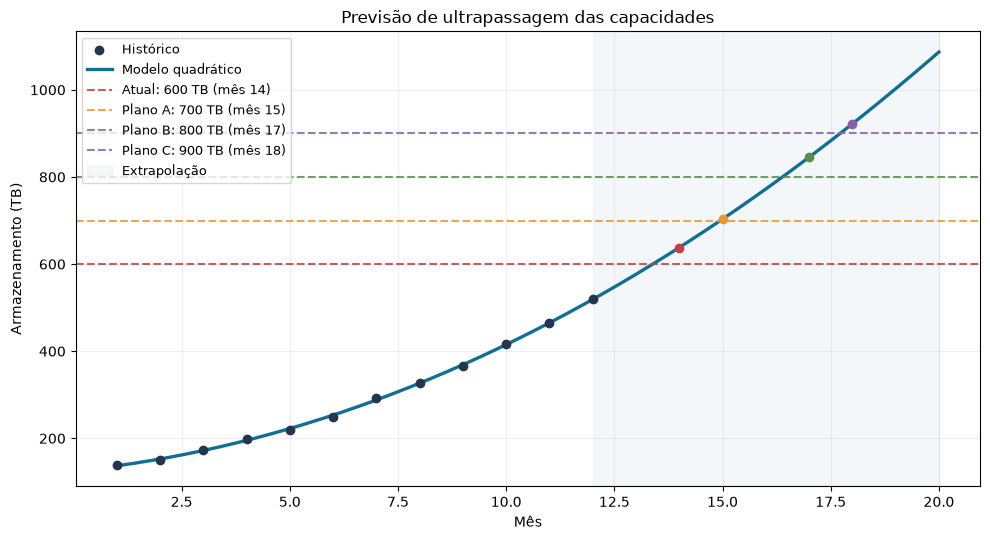

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
xs = [1 + k * .1 for k in range(191)]  # até 20
ax.scatter(meses, volumes, color='#26344e', label='Histórico', zorder=5)
ax.plot(xs, [funcao(t) for t in xs], color='#126f91', linewidth=2.4, label='Modelo quadrático')
cores = ['#bf4141', '#e79a31', '#5b8b52', '#8563a6']
for (nome, capacidade, cruzamento, primeiro, volume, it), cor in zip(resultado, cores):
    ax.axhline(capacidade, linestyle='--', color=cor, alpha=.85, label=f'{nome}: {capacidade:.0f} TB (mês {primeiro})')
    ax.scatter([primeiro], [volume], color=cor, zorder=6)
ax.axvspan(12, 20, color='#cbd7e2', alpha=.20, label='Extrapolação')
ax.set(xlabel='Mês', ylabel='Armazenamento (TB)', title='Previsão de ultrapassagem das capacidades')
ax.grid(alpha=.2); ax.legend(loc='upper left', fontsize=9); fig.tight_layout()
fig.savefig(RESULTADOS / 'limites_capacidade.png', dpi=180)
plt.show()

## 7. Diagnóstico dos resíduos

Para cada mês observado, o **resíduo** é $r_i=y_i-P_2(m_i)$, medido em TB. O gráfico a seguir mostra os resíduos em função do tempo e a linha de referência $r=0$.

**Como interpretar:** valores próximos de zero indicam boa proximidade aos dados históricos. Uma sequência de resíduos predominantemente positivos ou negativos, ou um padrão sistemático de curvatura, poderia indicar que o modelo não captou algum comportamento relevante. **Resíduos pequenos, isoladamente, não validam extrapolações futuras**. Com apenas 12 observações, esse diagnóstico é exploratório; não constitui teste formal de independência, normalidade ou ausência de sazonalidade.

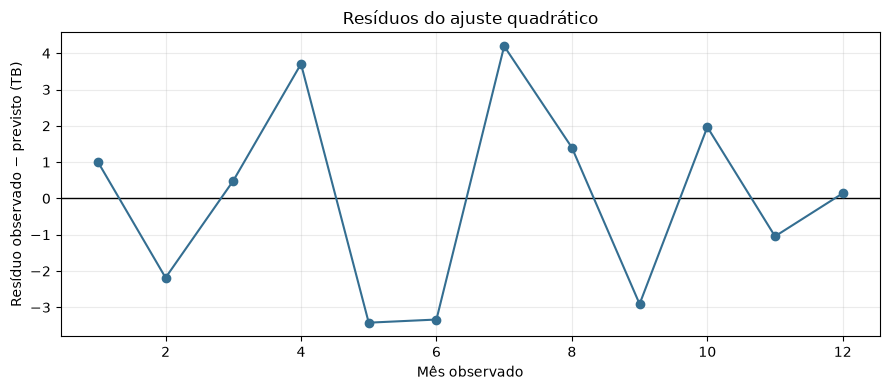

Resíduo máximo em módulo: 4.1941 TB


In [10]:
residuos = [y - avaliar_polinomio(modelo, m) for m, y in zip(meses, volumes)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.axhline(0, color='black', lw=1)
ax.plot(meses, residuos, 'o-', color='#346e91')
ax.set(xlabel='Mês observado', ylabel='Resíduo observado − previsto (TB)', title='Resíduos do ajuste quadrático')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(RESULTADOS / 'residuos_ajuste.png', dpi=160)
plt.show()
print(f'Resíduo máximo em módulo: {max(abs(r) for r in residuos):.4f} TB')

## 8. Discussão dos resultados, precisão e limitações

### 8.1. Respostas aos itens do enunciado

Com o modelo quadrático ajustado aos **12 meses**, obtemos uma estimativa de **576,62 TB no mês 13**. A capacidade atual de **600 TB** seria ultrapassada no **mês 14**. Para os planos de expansão, as primeiras ultrapassagens previstas são: **A (700 TB), mês 15; B (800 TB), mês 17; C (900 TB), mês 18**. A tabela calculada acima mostra também os cruzamentos contínuos e os valores estimados nos meses inteiros.

### 8.2. Três noções diferentes de erro

1. **Erro de ajuste:** o RMSE compara o polinômio com os 12 valores utilizados para ajustá-lo. Responde «o quanto a curva se aproxima do histórico?», não «quanto errará no futuro?».
2. **Erro de validação:** o Leave-One-Out e o teste temporal medem erros em observações omitidas do ajuste. O teste temporal é mais coerente com previsão, mas tem apenas três meses reservados.
3. **Erro numérico da Bisseção:** as tolerâncias de $10^{-9}$ controlam a aproximação da raiz de **$P_2(m)-C=0$**. Não significam que se conhece a data real de saturação com nove casas decimais.

### 8.3. Hipóteses e limites da previsão

- **Amostra curta:** 12 meses não permitem verificar com segurança sazonalidade, alterações estruturais ou comportamento de longo prazo.
- **Extrapolação:** os meses 13 a 18 ficam fora do intervalo observado; a incerteza tende a ser mais relevante quanto maior o horizonte, mesmo que o ajuste histórico seja excelente.
- **Modelo empírico:** um polinômio quadrático não é uma lei física de armazenamento. Migração de dados, exclusões, novos usuários, mudanças tecnológicas e políticas de retenção podem modificar a tendência.
- **Sem intervalo probabilístico:** não foi estimado um intervalo de previsão estatisticamente calibrado; os meses apresentados são **estimativas pontuais**, não garantias.
- **Planejamento operacional:** atingir o limite previsto não é um momento seguro para iniciar uma expansão. Seriam necessários margem de segurança, prazo de aquisição/implantação e atualização periódica das previsões.

### 8.4. Sensibilidade à escolha do modelo

Além de avaliar o grau 2, calculamos os primeiros meses de ultrapassagem com o **modelo linear**. A diferença entre esses resultados mostra que o mês previsto depende da **hipótese de crescimento**. Essa divergência não deve ser confundida com o erro de arredondamento nem com a tolerância da Bisseção; ela representa **incerteza de modelagem**. Os modelos não têm necessariamente a mesma credibilidade: o quadrático foi preferido pelas evidências de ajuste e validação disponíveis.

**Decisão final:** usar o modelo quadrático como referência para responder ao enunciado, mas interpretar seus cruzamentos como **alertas de planejamento condicionais**, não como datas certas de falha dos servidores.

### 8.5. Comparação dos meses de ultrapassagem por modelo

A tabela seguinte calcula, para cada capacidade, o primeiro mês inteiro com $P(m)>C$ usando o modelo linear e o quadrático. Ela torna visível o impacto da **escolha do grau** sobre as decisões de infraestrutura. A comparação é uma **análise de sensibilidade entre dois modelos**, não um intervalo de confiança estatístico.

In [11]:
print('Capacidade | 1º mês acima (linear) | 1º mês acima (quadrático)')
for nome, capacidade in capacidades.items():
    mes_linear = primeiro_mes_ultrapassagem(lambda m: avaliar_polinomio(modelos[1], m), capacidade, mes_inicial=13, limite_meses=120)
    mes_quad = primeiro_mes_ultrapassagem(lambda m: avaliar_polinomio(modelos[2], m), capacidade, mes_inicial=13, limite_meses=120)
    print(f'{nome:9} | {mes_linear:>21} | {mes_quad:>24}')

Capacidade | 1º mês acima (linear) | 1º mês acima (quadrático)
Atual     |                    16 |                       14
Plano A   |                    19 |                       15
Plano B   |                    22 |                       17
Plano C   |                    24 |                       18


## 9. Conclusão

O problema de planejamento de capacidade foi resolvido articulando métodos numéricos de acordo com a finalidade de cada etapa. A **aproximação polinomial por Mínimos Quadrados** forneceu uma função para representar a tendência dos dados; a **Eliminação de Gauss com pivotamento parcial** resolveu o sistema linear dos coeficientes; e a **Bisseção** localizou os instantes contínuos em que a demanda estimada iguala os limites. Uma verificação posterior de **desigualdade estrita em meses inteiros** permitiu responder corretamente à expressão «ultrapassar a capacidade».

A comparação entre graus 1, 2 e 3 considerou o **RMSE histórico**, a validação **Leave-One-Out**, uma **validação temporal** (treino nos meses 1–9; teste nos meses 10–12) e a simplicidade do modelo. Os resultados favorecem o **grau 2** para os dados e o teste disponíveis, sem demonstrar que o crescimento futuro seguirá necessariamente uma parábola.

O modelo final é, aproximadamente,

$$\boxed{P_2(m)=1{,}90765984m^2+9{,}92926823m+125{,}14568182\quad\text{(TB)}}.$$

Ele prevê **576,62 TB no mês 13** e a primeira ultrapassagem de **600 TB no mês 14**. Com as expansões A, B e C, os primeiros meses previstos acima dos respectivos limites são **15, 17 e 18**. Esses números são **previsões condicionais**: dependem do modelo escolhido e da permanência da tendência observada.

A principal conclusão para o planejamento é que **uma solução numérica muito precisa não equivale a uma previsão operacional igualmente precisa**. Para orientar uma expansão real, o responsável pela infraestrutura deveria incorporar novos dados mensalmente, revisar o modelo, considerar margens de segurança e iniciar ações antes do limite previsto.

## 10. Referências bibliográficas

**[1]** RUGGIERO, Márcia A. Gomes; LOPES, Vera Lúcia da Rocha. *Cálculo Numérico: Aspectos Teóricos e Computacionais*. 2. ed. São Paulo: Pearson/Makron Books. Referência para zeros de funções, sistemas lineares, interpolação e Mínimos Quadrados.

**[2]** Material didático da disciplina **Métodos Numéricos**, **Aula 11 — Eliminação de Gauss**, fornecido pelo professor. Referência para triangularização, pivotamento e substituição retroativa.

**[3]** Material didático da disciplina **Métodos Numéricos**, **Aula 15 — Aproximação Polinomial: Método dos Mínimos Quadrados**, fornecido pelo professor. Referência para ajuste de curvas e minimização de resíduos quadráticos.

**[4]** Material didático da disciplina **Métodos Numéricos**, **Aula 14 — Interpolação: Polinômio de Lagrange e Newton**, fornecido pelo professor. Utilizado na discussão sobre a diferença entre interpolação exata e ajuste aproximado.

**[5]** *Problema 3 — Planejamento de Capacidade de Servidores*. Enunciado e arquivos `armazenamento.csv` e `expansoes.csv`, fornecidos para a 2ª GQ.

**Critério bibliográfico:** as referências acima fundamentam os **conceitos e algoritmos**. Os valores numéricos, os gráficos, a comparação de graus e as conclusões específicas são resultados da **análise computacional dos dados do enunciado**, não resultados atribuídos às referências. Não foram incluídos artigos científicos sem consulta e verificação.